# Medicare NPI reconciliation: analysis and charts

Reads the small result tables built by the SQL in `../sql/` (the `work` dataset in BigQuery)
and draws the charts used in the README. It never reads the large public tables, so a full
run costs a few MB of BigQuery processing.

Run order: the SQL files `01` to `20` first, then this notebook. Charts are saved to `../results/charts/`.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from bq import query  # notebooks/bq.py: BigQuery sign-in + query -> DataFrame

CHARTS = pathlib.Path("..") / "results" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

# Chart colours (light theme): ink, chrome and one data hue.
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE = "#2a78d6"
# Severity uses the status colours; severity is also written in the legend,
# so colour never carries the meaning alone.
SEVERITY = {
    "high":   ("#d03b3b", "High: likely a data error"),
    "medium": ("#ec835a", "Medium: needs review"),
    "info":   (MUTED,     "Info: normal change since 2015"),
}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.facecolor": SURFACE,
    "figure.facecolor": SURFACE,
    "xtick.color": MUTED,
    "ytick.color": INK_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def tidy(ax, grid_axis="x"):
    """Recessive chrome: no top/right spines, hairline grid behind the bars."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def usd(v):
    if v >= 1e9:
        return f"${v / 1e9:.3g}B"
    if v >= 1e6:
        return f"${v / 1e6:.3g}M"
    if v >= 1e3:
        return f"${v / 1e3:.3g}K"
    return f"${v:,.0f}"


def save(fig, name):
    path = CHARTS / name
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor=SURFACE)
    print(f"saved {path}")

## 1. Every check at a glance

In [2]:
summary = query("SELECT * FROM `npi-reconciliation.work.dq_summary`")
for col in ["providers_checked", "providers_failed"]:
    summary[col] = summary[col].astype(int)
summary["allowed_usd_affected"] = summary["allowed_usd_affected"].astype(float)

rank = {"high": 0, "medium": 1, "info": 2}
summary = (summary.assign(sev=summary["severity"].map(rank))
                  .sort_values(["sev", "check_id"])
                  .reset_index(drop=True))
summary[["check_id", "check_name", "severity", "providers_checked",
         "providers_failed", "pct_failed", "allowed_usd_affected"]]

,check_id,check_name,severity,providers_checked,providers_failed,pct_failed,allowed_usd_affected
0,10,ID not in registry,high,968417,2,0.000,8.181800e+04
1,11,Invalid NPI (check digit),high,968417,0,0.000,0.000000e+00
2,12a,Deactivated before 2015,high,968415,13,0.001,5.978920e+05
3,13,Person vs organisation,high,933398,0,0.000,0.000000e+00
4,17,Billed before ID was issued,high,933398,2,0.000,4.689000e+03
5,12b,Deactivated during 2015,medium,968415,751,0.078,2.884291e+07
6,16,Unusual specialty,medium,932737,18744,2.010,1.778984e+09
7,12c,Deactivated after 2015,info,968415,34253,3.537,2.910776e+09
8,14a,Different state,info,933387,79027,8.467,6.097303e+09
9,14b,"Same state, different ZIP",info,933387,140463,15.049,1.494646e+10


saved ..\results\charts\01_checks_overview.png


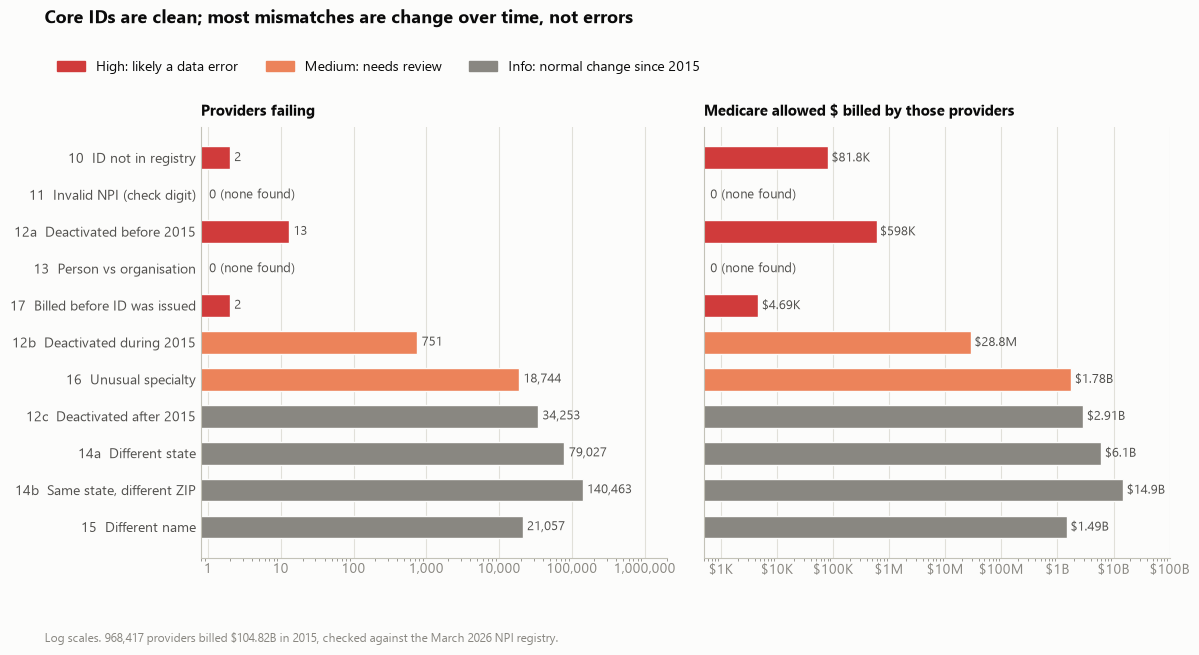

In [3]:
# Plot top-to-bottom in table order (most serious first).
s = summary.iloc[::-1].reset_index(drop=True)
labels = s["check_id"] + "  " + s["check_name"]
colors = [SEVERITY[v][0] for v in s["severity"]]
y = np.arange(len(s))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.6), sharey=True,
                               gridspec_kw={"wspace": 0.08})

panels = [
    (ax1, s["providers_failed"].to_numpy(float), "Providers failing", (0.8, 2e6),
     lambda v: f"{int(v):,}"),
    (ax2, s["allowed_usd_affected"].to_numpy(float), "Medicare allowed $ billed by those providers",
     (5e2, 1e11), usd),
]
for ax, values, title, xlim, fmt in panels:
    positive = values > 0
    ax.barh(y[positive], values[positive], height=0.62,
            color=np.array(colors)[positive], edgecolor=SURFACE, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(*xlim)
    for yi, v in zip(y, values):
        ax.text(v * 1.15 if v > 0 else xlim[0] * 1.3, yi,
                fmt(v) if v > 0 else "0 (none found)",
                va="center", ha="left", fontsize=9, color=INK_2)
    ax.set_title(title, fontsize=10.5, color=INK, pad=8)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _, f=fmt: f(v)))
    tidy(ax)

ax1.set_yticks(y, labels)
fig.legend(handles=[Patch(color=c, label=l) for c, l in SEVERITY.values()],
           loc="upper left", bbox_to_anchor=(0.0, 1.02), ncol=3, frameon=False)
fig.suptitle("Core IDs are clean; most mismatches are change over time, not errors",
             x=0.0, y=1.09, ha="left", fontsize=13, fontweight="bold")
fig.text(0.0, -0.04, "Log scales. 968,417 providers billed $104.82B in 2015, checked against the "
         "March 2026 NPI registry.", fontsize=8.5, color=MUTED)
save(fig, "01_checks_overview.png")
plt.show()

The three high-severity real-error checks (10, 11, 13) find almost nothing, so the IDs themselves are reliable.
The only high-severity findings are tiny and specific: 13 NPIs deactivated years before billing, and 2 billed before they were issued.
The big counts are all *info*: providers who moved or changed their name after 2015.

## 2. When were the 2015 billers deactivated?

In [4]:
deact = query("""
    SELECT EXTRACT(YEAR FROM npi_deactivation_date) AS year,
           deactivation_group,
           COUNT(*) AS providers,
           SUM(allowed_usd) AS allowed_usd
    FROM `npi-reconciliation.work.chk_12_deactivated`
    GROUP BY 1, 2
    ORDER BY 1
""")
deact["year"] = deact["year"].astype(int)
deact["providers"] = deact["providers"].astype(int)
deact

,year,deactivation_group,providers,allowed_usd
0,2005,before_2015,4,2.355409e+05
1,2006,before_2015,4,1.044447e+05
2,2007,before_2015,4,1.915619e+05
3,2008,before_2015,1,6.634481e+04
4,2015,during_2015,751,2.884291e+07
5,2016,after_2015,1511,1.212207e+08
6,2017,after_2015,1850,1.669452e+08
7,2018,after_2015,2591,1.816039e+08
8,2019,after_2015,3560,2.415196e+08
9,2020,after_2015,4207,2.918712e+08


saved ..\results\charts\02_deactivations_by_year.png


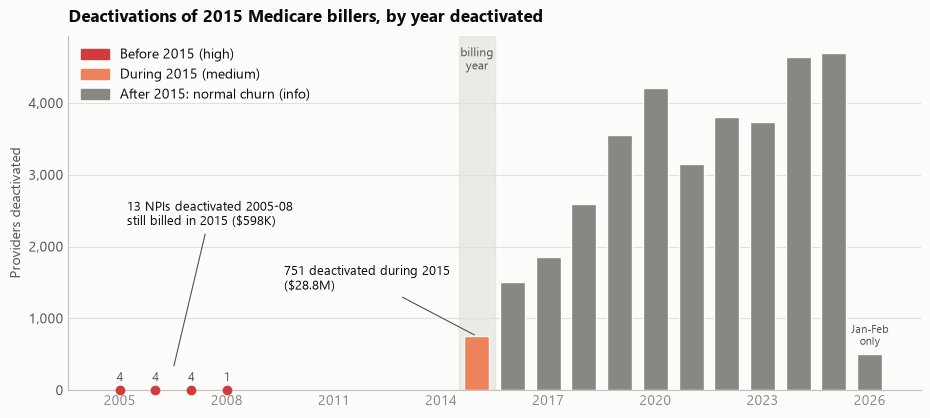

In [5]:
group_color = {"before_2015": SEVERITY["high"][0],
               "during_2015": SEVERITY["medium"][0],
               "after_2015":  SEVERITY["info"][0]}
years = np.arange(deact["year"].min(), deact["year"].max() + 1)
by_year = deact.set_index("year").reindex(years)

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(years, by_year["providers"].fillna(0), width=0.7,
       color=[group_color.get(g, MUTED) for g in by_year["deactivation_group"]],
       edgecolor=SURFACE, linewidth=1)
ax.axvspan(2014.5, 2015.5, color=GRID, alpha=0.6, zorder=0)
ax.text(2015, ax.get_ylim()[1] * 0.97, "billing\nyear", ha="center", va="top",
        fontsize=8.5, color=INK_2)

before = deact[deact["deactivation_group"] == "before_2015"]
during = deact[deact["deactivation_group"] == "during_2015"]
# These bars (1-4 providers) are too small to see at this scale: mark them
# on the baseline and write the count above each.
ax.scatter(before["year"], np.zeros(len(before)), s=36, color=group_color["before_2015"],
           zorder=3, clip_on=False)
for yr, n in zip(before["year"], before["providers"]):
    ax.text(yr, 90, str(n), ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.annotate(f"{before['providers'].sum()} NPIs deactivated 2005-08\nstill billed in 2015 "
            f"({usd(before['allowed_usd'].sum())})",
            xy=(2006.5, 300), xytext=(2005.2, 2300), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))
last = years.max()
ax.text(last, by_year.loc[last, "providers"] + 80, "Jan-Feb\nonly", ha="center", va="bottom",
        fontsize=8, color=INK_2)
ax.annotate(f"{during['providers'].sum()} deactivated during 2015\n({usd(during['allowed_usd'].sum())})",
            xy=(2015, during['providers'].sum()), xytext=(2009.6, 1400), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))

ax.set_xticks(years[::3])
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylabel("Providers deactivated")
ax.set_title("Deactivations of 2015 Medicare billers, by year deactivated", pad=10)
ax.legend(handles=[Patch(color=group_color["before_2015"], label="Before 2015 (high)"),
                   Patch(color=group_color["during_2015"], label="During 2015 (medium)"),
                   Patch(color=group_color["after_2015"],  label="After 2015: normal churn (info)")],
          loc="upper left", frameon=False)
tidy(ax, grid_axis="y")
save(fig, "02_deactivations_by_year.png")
plt.show()

Deactivations after 2015 rise steadily, from about 1,500 a year to about 4,700, which is what normal retirement and practice closures look like.
The 13 deactivated before 2015 are too few to see as bars, which is the point: they are a short list to investigate, not a trend.

## 3. Where did providers move?

In [6]:
moves = query("""
    SELECT medicare_state AS state_2015, registry_state AS state_now, COUNT(*) AS providers
    FROM `npi-reconciliation.work.chk_14_location`
    WHERE location_result = 'state_mismatch'
    GROUP BY 1, 2
    ORDER BY providers DESC
    LIMIT 12
""")
moves["providers"] = moves["providers"].astype(int)
moves["move"] = moves["state_2015"] + " → " + moves["state_now"]
moves

,state_2015,state_now,providers,move
0,NY,FL,807,NY → FL
1,NY,NJ,716,NY → NJ
2,PA,NJ,582,PA → NJ
3,NY,CA,547,NY → CA
4,PA,FL,473,PA → FL
5,OH,FL,420,OH → FL
6,IL,FL,392,IL → FL
7,NJ,NY,366,NJ → NY
8,NY,PA,354,NY → PA
9,IL,CA,351,IL → CA


saved ..\results\charts\03_top_state_moves.png


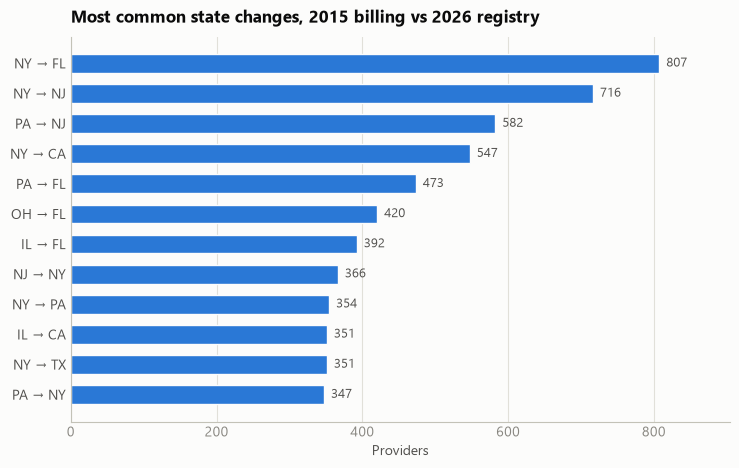

In [7]:
m = moves.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(m["move"], m["providers"], height=0.62, color=BLUE, edgecolor=SURFACE, linewidth=1)
for yi, v in enumerate(m["providers"]):
    ax.text(v + 10, yi, f"{v:,}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, m["providers"].max() * 1.12)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Most common state changes, 2015 billing vs 2026 registry", pad=10)
ax.set_xlabel("Providers")
tidy(ax)
save(fig, "03_top_state_moves.png")
plt.show()

The top moves follow known migration patterns: out of New York, Pennsylvania, Ohio and Illinois, towards Florida, New Jersey,
California and Texas, plus moves within metro areas that span two states (NY and NJ, PA and NJ).
That pattern is strong evidence that state mismatches are real relocations, not data errors.

## 4. Which provider types have the most unusual specialties?

In [8]:
spec = query("""
    SELECT provider_type,
           ANY_VALUE(usual_classification) AS usual_classification,
           ANY_VALUE(type_providers)       AS type_providers,
           COUNT(*)                        AS flagged
    FROM `npi-reconciliation.work.chk_16_specialty_mismatch`
    GROUP BY provider_type
""")
spec[["type_providers", "flagged"]] = spec[["type_providers", "flagged"]].astype(int)
spec["pct_flagged"] = spec["flagged"] / spec["type_providers"] * 100
big = spec[spec["type_providers"] >= 5000].sort_values("pct_flagged", ascending=False).head(15)
big

,provider_type,usual_classification,type_providers,flagged,pct_flagged
25,General Surgery,Surgery,18060,760,4.208195
30,Physical Medicine and Rehabilitation,Physical Medicine & Rehabilitation,7323,273,3.727980
24,Internal Medicine,Internal Medicine,93338,3231,3.461613
23,Emergency Medicine,Emergency Medicine,39562,1198,3.028158
4,Nurse Practitioner,Nurse Practitioner,77414,1961,2.533134
47,Nephrology,Internal Medicine,7838,186,2.373054
0,Family Practice,Family Medicine,77657,1837,2.365530
10,Psychiatry,Psychiatry & Neurology,20012,468,2.338597
6,Pathology,Pathology,11051,243,2.198896
7,CRNA,"Nurse Anesthetist, Certified Registered",33177,679,2.046599


saved ..\results\charts\04_unusual_specialty_by_type.png


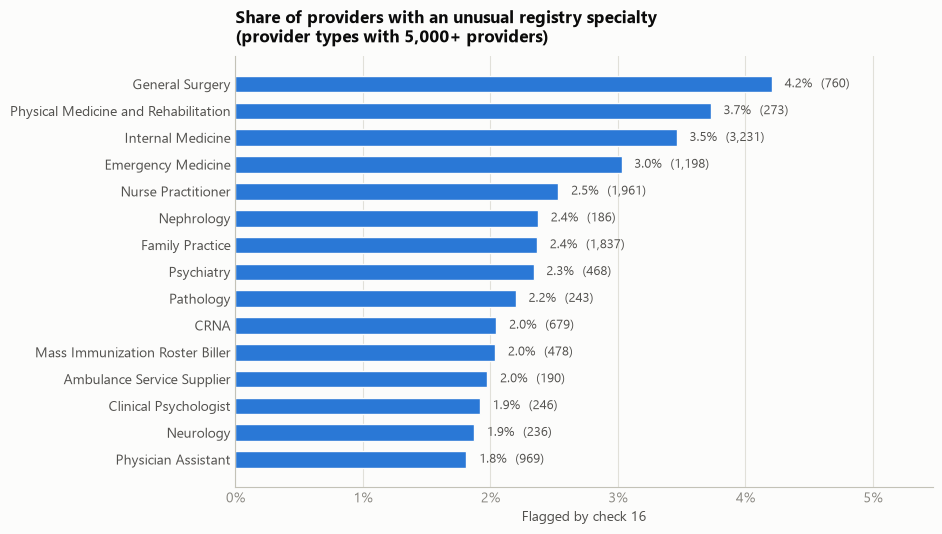

In [9]:
b = big.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(b["provider_type"], b["pct_flagged"], height=0.62, color=BLUE, edgecolor=SURFACE, linewidth=1)
for yi, (pct, n) in enumerate(zip(b["pct_flagged"], b["flagged"])):
    ax.text(pct + 0.1, yi, f"{pct:.1f}%  ({n:,})", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, b["pct_flagged"].max() * 1.3)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Share of providers with an unusual registry specialty\n"
             "(provider types with 5,000+ providers)", pad=10)
ax.set_xlabel("Flagged by check 16")
tidy(ax)
save(fig, "04_unusual_specialty_by_type.png")
plt.show()

Broad provider types such as General Surgery, Physical Medicine and Internal Medicine have the highest flag rates (3.5-4.2%),
because their providers register under many different sub-specialties. Even the highest rate is under 5%, and narrow types
are flagged far less often. Check 16 is a review list, not an error count.